<a href="https://colab.research.google.com/github/RaczNikoletta/Artificial-intelligence/blob/main/beadando_emberdsv2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Data Loading and Dataset Audit

## 1.1. A felhasznált adathalmaz bemutatása

A projekt során az EMBER 2018 v2 adathalmazt használom, amely Windows Portable Executable (PE) fájlokból kinyert statikus jellemzőket tartalmaz.

A feladat egy bináris osztályozási probléma, amelynek során két kategóriát különböztetek meg:

- **Benign (0):** ártalmatlan, legitim fájlok.
- **Malware (1):** kártékony fájlok.

Az adathalmaz eredeti jellemzővektora 2381 dimenzióból áll. Ezek különböző információkat reprezentálnak, például a PE fejlécet, a szekciókat, az importált függvényeket és a bináris állományok statisztikai tulajdonságait.

Az eredeti, címkézetlen mintákat (-1 címke) a felügyelt tanulási kísérletekből kizárom.

## 1.2. Adatelőkészítés célja

Az adatbetöltés során fontos szempont a reprezentatív mintavételezés és a memóriatakarékos feldolgozás.

A mintavételezés a teljes állomány feldolgozásával történik, így elkerülhető, hogy az adathalmaz sorrendje befolyásolja a kiválasztott mintákat.

A tanítóadatokból külön validációs halmazt hozok létre. A végleges teszthalmazt az eredeti tesztállományból választom ki, és a modellfejlesztés során nem használom fel.

In [1]:
import os
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split

# Reprodukálhatóság
RANDOM_STATE = 42

# Mintavételezési beállítások
TRAIN_SAMPLE_SIZE = 40_000
TEST_SAMPLE_SIZE = 10_000
BATCH_SIZE = 5_000

# Megjelenítési beállítások
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Konfiguráció sikeresen betöltve.")

Konfiguráció sikeresen betöltve.


1.3. Adathalmaz letöltése és ellenőrzése

In [2]:
# EMBER 2018 v2 letöltése
print("EMBER 2018 v2 dataset ellenőrzése...")

download_path = Path(
    kagglehub.dataset_download(
        "dhoogla/ember-2018-v2-features"
    )
)

def find_dataset_file(root, filename):
    matches = list(root.rglob(filename))

    if not matches:
        raise FileNotFoundError(
            f"Nem található: {filename}"
        )

    return matches[0]


train_file = find_dataset_file(
    download_path,
    "train_ember_2018_v2_features.parquet"
)

test_file = find_dataset_file(
    download_path,
    "test_ember_2018_v2_features.parquet"
)

print("Train:", train_file)
print("Test:", test_file)

EMBER 2018 v2 dataset ellenőrzése...


100%|██████████| 2.23G/2.23G [00:28<00:00, 84.4MB/s]

Extracting files...


Train: /root/.cache/kagglehub/datasets/dhoogla/ember-2018-v2-features/versions/2/train_ember_2018_v2_features.parquet
Test: /root/.cache/kagglehub/datasets/dhoogla/ember-2018-v2-features/versions/2/test_ember_2018_v2_features.parquet


In [3]:
train_parquet = pq.ParquetFile(train_file)
test_parquet = pq.ParquetFile(test_file)

train_columns = train_parquet.schema.names
test_columns = test_parquet.schema.names

# Címkeoszlop azonosítása
label_candidates = [
    col for col in train_columns
    if col.lower() == "label"
]

if len(label_candidates) != 1:
    raise ValueError("Nem sikerült azonosítani a Label oszlopot.")

LABEL_COL = label_candidates[0]

FEATURE_COLS = [
    col for col in train_columns
    if col != LABEL_COL
]

# Szerkezeti ellenőrzések
assert LABEL_COL in test_columns
assert set(train_columns) == set(test_columns)
assert len(FEATURE_COLS) == 2381

print("Train sorok:", train_parquet.metadata.num_rows)
print("Test sorok:", test_parquet.metadata.num_rows)
print("Feature-ök száma:", len(FEATURE_COLS))
print("Címkeoszlop:", LABEL_COL)

Train sorok: 799912
Test sorok: 199956
Feature-ök száma: 2381
Címkeoszlop: Label


In [4]:
def count_dataset_labels(file_path):

    parquet_file = pq.ParquetFile(file_path)

    columns = parquet_file.schema.names

    label_col = next(
        col for col in columns
        if col.lower() == "label"
    )

    counts = {
        0: 0,
        1: 0,
        -1: 0
    }

    total_rows = 0

    for batch in parquet_file.iter_batches(
        batch_size=BATCH_SIZE,
        columns=[label_col]
    ):

        labels = batch.column(0).to_numpy(
            zero_copy_only=False
        )

        total_rows += len(labels)

        for label in counts:
            counts[label] += int(
                np.count_nonzero(labels == label)
            )

    return counts, total_rows


train_counts, train_total = count_dataset_labels(train_file)
test_counts, test_total = count_dataset_labels(test_file)

print("TRAIN LABEL DISTRIBUTION")
print(train_counts)

print("\nTEST LABEL DISTRIBUTION")
print(test_counts)

print("\nÖsszes train rekord:", train_total)
print("Összes test rekord:", test_total)

TRAIN LABEL DISTRIBUTION
{0: 299991, 1: 299929, -1: 199992}

TEST LABEL DISTRIBUTION
{0: 99985, 1: 99971, -1: 0}

Összes train rekord: 799912
Összes test rekord: 199956


1.5. Reprezentatív mintavételezés
Ez lesz az első igazán fontos fejlesztés.

Ahelyett, hogy az első megfelelő batch-ekből válogatnánk, az egész Parquet állományt feldolgozzuk.

A módszer neve reservoir sampling, pontosabban itt véletlen prioritások alapján tartjuk meg a mintákat.

Az algoritmus minden rekordhoz véletlen prioritást rendel, és az egyes osztályokon belül a legkisebb prioritású rekordokat tartja meg.

Így az állomány sorrendje nem határozza meg, mely minták kerülnek a tanulóhalmazba.

Először készítünk egy függvényt, amely az eredeti osztályarányokat megtartva osztja el a mintavételi keretet:

In [5]:
def allocate_sample_counts(class_counts, sample_size):

    total = sum(class_counts.values())

    if total == 0:
        raise ValueError("Nincs címkézett adat.")

    sample_size = min(sample_size, total)

    quotas = {
        label: int(
            sample_size * count / total
        )
        for label, count in class_counts.items()
    }

    # A kerekítési különbség korrigálása
    remaining = sample_size - sum(quotas.values())

    order = sorted(
        class_counts,
        key=lambda label: (
            sample_size * class_counts[label] / total
            - quotas[label]
        ),
        reverse=True
    )

    for label in order:
        if remaining == 0:
            break

        if quotas[label] < class_counts[label]:
            quotas[label] += 1
            remaining -= 1

    return quotas

Mintavételezés

In [6]:
def load_representative_sample(
    file_path,
    sample_size,
    random_state=42
):

    rng = np.random.default_rng(random_state)

    parquet_file = pq.ParquetFile(file_path)

    columns = parquet_file.schema.names

    label_col = next(
        col for col in columns
        if col.lower() == "label"
    )

    feature_cols = [
        col for col in columns
        if col != label_col
    ]

    # Teljes állomány címkéinek megszámlálása
    class_counts, total_rows = count_dataset_labels(
        file_path
    )

    # A -1 címkét kizárjuk
    labeled_counts = {
        0: class_counts[0],
        1: class_counts[1]
    }

    quotas = allocate_sample_counts(
        labeled_counts,
        sample_size
    )

    print("Mintavételi keretek:", quotas)

    # Osztályonkénti tárolók
    reservoirs = {
        0: np.empty(
            (0, len(feature_cols)),
            dtype=np.float32
        ),
        1: np.empty(
            (0, len(feature_cols)),
            dtype=np.float32
        )
    }

    priorities = {
        0: np.empty(0),
        1: np.empty(0)
    }

    # A teljes Parquet állomány feldolgozása
    for batch in parquet_file.iter_batches(
        batch_size=BATCH_SIZE,
        columns=feature_cols + [label_col]
    ):

        df_batch = batch.to_pandas()

        y_batch = df_batch[label_col].to_numpy()

        X_batch = df_batch[feature_cols].to_numpy(
            dtype=np.float32,
            copy=False
        )

        for label in [0, 1]:

            quota = quotas[label]

            if quota == 0:
                continue

            mask = y_batch == label

            if not np.any(mask):
                continue

            X_class = X_batch[mask]

            new_priorities = rng.random(
                len(X_class)
            )

            # Korábbi és új minták egyesítése
            combined_X = np.concatenate([
                reservoirs[label],
                X_class
            ])

            combined_priorities = np.concatenate([
                priorities[label],
                new_priorities
            ])

            # A legkisebb prioritású minták megtartása
            if len(combined_priorities) > quota:

                keep = np.argpartition(
                    combined_priorities,
                    quota - 1
                )[:quota]

                reservoirs[label] = combined_X[keep]
                priorities[label] = combined_priorities[keep]

            else:

                reservoirs[label] = combined_X
                priorities[label] = combined_priorities

        del df_batch, X_batch, y_batch
        gc.collect()

    # Minták összefűzése
    X_sample = np.concatenate([
        reservoirs[0],
        reservoirs[1]
    ])

    y_sample = np.concatenate([
        np.zeros(len(reservoirs[0]), dtype=np.int8),
        np.ones(len(reservoirs[1]), dtype=np.int8)
    ])

    # Véletlenszerű sorrend
    shuffle_idx = rng.permutation(len(y_sample))

    X_sample = X_sample[shuffle_idx]
    y_sample = y_sample[shuffle_idx]

    print("\nMintavételezés kész.")
    print("Minták száma:", len(y_sample))
    print("Feature-ök száma:", X_sample.shape[1])
    print("Benign:", np.sum(y_sample == 0))
    print("Malware:", np.sum(y_sample == 1))

    return X_sample, y_sample, feature_cols

In [7]:
# Ellenőrizzük a feature-ök sorrendjét
test_feature_cols = [
    col for col in test_columns
    if col != LABEL_COL
]

if FEATURE_COLS != test_feature_cols:
    raise ValueError(
        "A train és test feature-ök sorrendje eltér!"
    )

# Train minták
X_train_pool, y_train_pool, feature_names = (
    load_representative_sample(
        train_file,
        sample_size=TRAIN_SAMPLE_SIZE,
        random_state=RANDOM_STATE
    )
)

# Test minták
X_test, y_test, test_feature_names = (
    load_representative_sample(
        test_file,
        sample_size=TEST_SAMPLE_SIZE,
        random_state=RANDOM_STATE + 1
    )
)

assert feature_names == test_feature_names

print("\nVégleges alakzatok:")
print("Train pool:", X_train_pool.shape)
print("Test:", X_test.shape)

Mintavételi keretek: {0: 20002, 1: 19998}

Mintavételezés kész.
Minták száma: 40000
Feature-ök száma: 2381
Benign: 20002
Malware: 19998
Mintavételi keretek: {0: 5000, 1: 5000}

Mintavételezés kész.
Minták száma: 10000
Feature-ök száma: 2381
Benign: 5000
Malware: 5000

Végleges alakzatok:
Train pool: (40000, 2381)
Test: (10000, 2381)


A természetes osztályarányok megőrzése azért előnyös, mert később valósághűbb tesztelést tesz lehetővé. Ha az osztályok aránya nagyon eltérő, azt a modell tanításakor külön kezelhetjük.

1.7. Train, validation és test szétválasztása
A korábbi notebookodban közvetlenül a train és test készletekkel dolgoztál.

Most bevezetünk egy harmadik halmazt is.
- Train: a modell megtanulja a mintázatokat.
- Validation: ezen választjuk ki a legjobb modellt és paramétereket.
- Test: csak a végső értékelésre használjuk.
A 40 000 tanító mintából 80–20%-os felosztást készítünk.

In [8]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_pool,
    y_train_pool,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train_pool
)

# A felesleges teljes tanító tömb felszabadítása
del X_train_pool, y_train_pool
gc.collect()

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (32000, 2381) (32000,)
Validation: (8000, 2381) (8000,)
Test: (10000, 2381) (10000,)


1.8. Dataset audit
Most ellenőrizzük, hogy milyen minőségű adatokkal fogunk dolgozni.

In [9]:
def dataset_audit(name, X, y):

    class_counts = pd.Series(y).value_counts().reindex(
        [0, 1],
        fill_value=0
    )

    print(f"\n{'='*45}")
    print(f"DATASET AUDIT: {name}")
    print(f"{'='*45}")

    print("Minták száma:", X.shape[0])
    print("Feature-ök száma:", X.shape[1])
    print("Adattípus:", X.dtype)

    print("\nOsztályeloszlás:")
    print(class_counts.rename({
        0: "Benign",
        1: "Malware"
    }))

    print("\nOsztályarány (%):")
    print(
        (class_counts / len(y) * 100).round(2)
    )

    nan_count = np.isnan(X).sum()
    inf_count = np.isinf(X).sum()

    print("\nAdatminőség:")
    print("NaN értékek:", nan_count)
    print("Végtelen értékek:", inf_count)

    print(
        "Olyan feature-ök, amelyekben van NaN:",
        np.isnan(X).any(axis=0).sum()
    )

    print(
        "Olyan feature-ök, amelyekben van Inf:",
        np.isinf(X).any(axis=0).sum()
    )

    print("Címkék:", np.unique(y))

    return {
        "dataset": name,
        "samples": X.shape[0],
        "features": X.shape[1],
        "benign": int(class_counts[0]),
        "malware": int(class_counts[1]),
        "nan": int(nan_count),
        "inf": int(inf_count)
    }


audit_results = []

audit_results.append(
    dataset_audit("Train", X_train, y_train)
)

audit_results.append(
    dataset_audit("Validation", X_val, y_val)
)

audit_results.append(
    dataset_audit("Test", X_test, y_test)
)

audit_df = pd.DataFrame(audit_results)

display(audit_df)


DATASET AUDIT: Train
Minták száma: 32000
Feature-ök száma: 2381
Adattípus: float32

Osztályeloszlás:
Benign     16002
Malware    15998
Name: count, dtype: int64

Osztályarány (%):
0    50.01
1    49.99
Name: count, dtype: float64

Adatminőség:
NaN értékek: 0
Végtelen értékek: 0
Olyan feature-ök, amelyekben van NaN: 0
Olyan feature-ök, amelyekben van Inf: 0
Címkék: [0 1]

DATASET AUDIT: Validation
Minták száma: 8000
Feature-ök száma: 2381
Adattípus: float32

Osztályeloszlás:
Benign     4000
Malware    4000
Name: count, dtype: int64

Osztályarány (%):
0    50.0
1    50.0
Name: count, dtype: float64

Adatminőség:
NaN értékek: 0
Végtelen értékek: 0
Olyan feature-ök, amelyekben van NaN: 0
Olyan feature-ök, amelyekben van Inf: 0
Címkék: [0 1]

DATASET AUDIT: Test
Minták száma: 10000
Feature-ök száma: 2381
Adattípus: float32

Osztályeloszlás:
Benign     5000
Malware    5000
Name: count, dtype: int64

Osztályarány (%):
0    50.0
1    50.0
Name: count, dtype: float64

Adatminőség:
NaN értékek:

,dataset,samples,features,benign,malware,nan,inf
0,Train,32000,2381,16002,15998,0,0
1,Validation,8000,2381,4000,4000,0,0
2,Test,10000,2381,5000,5000,0,0


1.9. Az osztályeloszlás vizualizációja

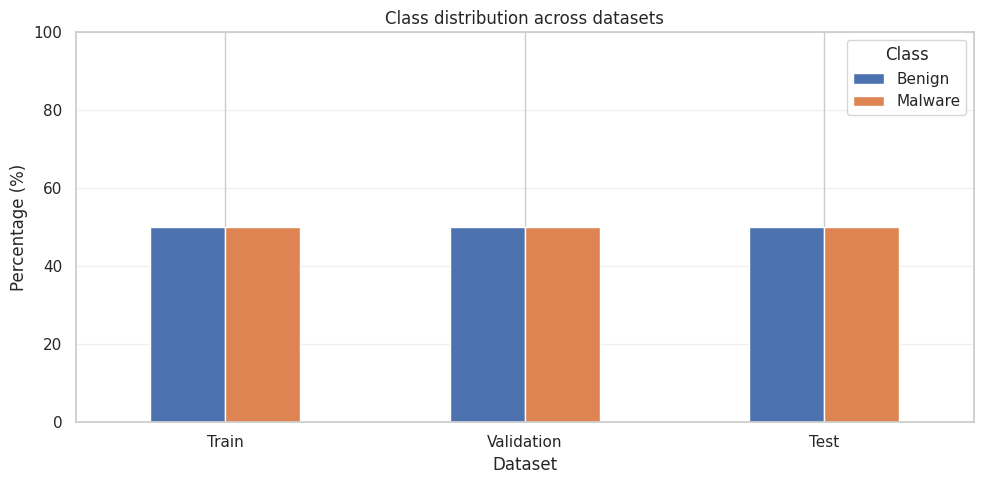

In [10]:
distributions = {}

for name, y in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:

    counts = pd.Series(y).value_counts(normalize=True)

    distributions[name] = [
        counts.get(0, 0) * 100,
        counts.get(1, 0) * 100
    ]

distribution_df = pd.DataFrame(
    distributions,
    index=["Benign", "Malware"]
).T

ax = distribution_df.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("Class distribution across datasets")
plt.ylabel("Percentage (%)")
plt.xlabel("Dataset")
plt.legend(title="Class")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

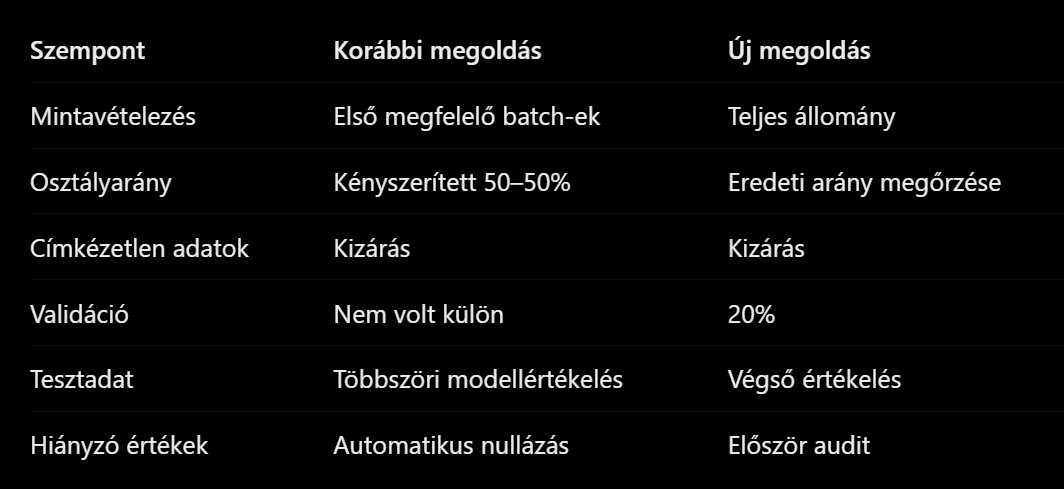